<a href="https://colab.research.google.com/github/ohood95/ohood95.github.io/blob/master/03_models_and_fusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 — Susceptibility models, Face-A vs Face-B, and multimodal fusion
**Phishing Susceptibility Detection — Ohud Aljohani, FCIT, KAU**

<div dir="rtl">

**ما يجيب عنه هذا الدفتر:**
| السؤال | المقارنة |
|---|---|
| **RQ2** هل تعابير الوجه وحركة الماوس تتنبأ بقابلية الوقوع؟ | كل وسيلة وحدها مقابل خط الأساس |
| **قرار المشرفة (العنوان)** أيهما أفضل: Emotions أم Blendshapes؟ | **Face-A (emotions)** مقابل **Face-B (blendshapes)** بنفس النموذج ونفس التقسيم |
| **RQ3 / الفرضية** هل الدمج أفضل من كل وسيلة منفردة؟ | Mouse + Face مقابل أفضل وسيلة منفردة |
| **الهدف 7** متى يمكن الكشف؟ | الأداء مقابل طول النافذة الزمنية (أول 3، 5، 8 ثوانٍ…) |

**بروتوكول التقييم:** Leave-One-Subject-Out — كل مشارك يُختبر بنموذج لم يرَ أي محاولة له. كل ما يُتعلَّم (التطبيع، اختيار الخصائص، أوزان الدمج) يُتعلَّم داخل بيانات التدريب فقط.

**التصميم المُسجَّل مسبقًا (Pre-registered):** لتجنّب تحيّز اختيار أفضل نتيجة من عشرات التجارب، نحدد **قبل** رؤية النتائج النموذج الرئيسي لاختبار الفرضيات (`PRIMARY_MODEL`). بقية النماذج تُعرض كنتائج ثانوية.
</div>

In [21]:
import os, sys
from google.colab import drive
drive.mount("/content/drive")
PROJECT_DIR = "/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility"   # >>> EDIT
sys.path.insert(0, f"{PROJECT_DIR}/src")
RESULTS_DIR = f"{PROJECT_DIR}/results"
!pip -q install xgboost shap

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
print("PROJECT_DIR exists:", os.path.exists(PROJECT_DIR))
print("src exists:", os.path.exists(f"{PROJECT_DIR}/src"))
print("psd exists:", os.path.exists(f"{PROJECT_DIR}/src/psd"))

if os.path.exists(f"{PROJECT_DIR}/src/psd"):
    print("\nContents of psd:")
    print(os.listdir(f"{PROJECT_DIR}/src/psd"))

PROJECT_DIR exists: True
src exists: True
psd exists: True

Contents of psd:
['io.py', 'constants.py', 'modeling.py', '__init__.py', 'face_features.py', 'synthetic.py', 'realtime.py', 'stats.py', 'fer', 'dataset.py', 'mouse_features.py']


In [25]:
import sys
import importlib

OLD_SRC = "/content/drive/MyDrive/phishing_susceptibility/src"
NEW_SRC = "/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility/src"

# احذف المسار القديم
while OLD_SRC in sys.path:
    sys.path.remove(OLD_SRC)

# ضع المسار الصحيح في البداية
if NEW_SRC in sys.path:
    sys.path.remove(NEW_SRC)

sys.path.insert(0, NEW_SRC)

# احذف psd القديم من الذاكرة إذا كان قد تم تحميله
for name in list(sys.modules):
    if name == "psd" or name.startswith("psd."):
        del sys.modules[name]

importlib.invalidate_caches()

import psd
print("psd loaded from:")
print(psd.__file__)

psd loaded from:
/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility/src/psd/__init__.py


In [29]:
import os

print("Files in results:")
print(os.listdir(RESULTS_DIR))

print("\nSynthetic module:")
print(f"{PROJECT_DIR}/src/psd/synthetic.py")
print(os.path.exists(f"{PROJECT_DIR}/src/psd/synthetic.py"))

Files in results:
['models_SYNTHETIC']

Synthetic module:
/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility/src/psd/synthetic.py
True


In [30]:
from psd import synthetic
import inspect

print(inspect.getsource(synthetic))

"""Synthetic sessions in exactly the raw format the experiment app writes.

!!! FOR PIPELINE DRY-RUNS ONLY — NEVER REPORT THESE NUMBERS AS RESULTS !!!

Purpose: test feature extraction, LOSO evaluation, fusion, statistics and the
real-time scorer end-to-end before real participants are recorded. The
generative model is a simple latent-suspicion model, so performance on it says
nothing about real human behaviour.

Generative story per trial
    participant trait  s_i ~ N(0,1)            (higher = more susceptible)
    stimulus cue       c_j                     (higher = more obvious phishing)
    latent suspicion   q = sigmoid(c_j - s_i + noise)
    phishing decision  submit ~ Bernoulli(sigmoid(1.6 (s_i - c_j) - 0.2 + noise))
    behaviour          suspicion -> more pauses, longer URL-bar inspection,
                       curvier paths, more brow lowering / lid tightening;
                       emotion probabilities shift only weakly.
"""
from __future__ import annotations

import jso

In [31]:
import os

ROOT = PROJECT_DIR

for root, dirs, files in os.walk(ROOT):
    for file in files:
        if file.endswith((".py", ".ipynb")):
            path = os.path.join(root, file)
            try:
                with open(path, "r", encoding="utf-8") as f:
                    txt = f.read()
                if "generate_sessions" in txt and not path.endswith("synthetic.py"):
                    print(path)
            except:
                pass

/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility/tests/test_pipeline.py
/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility/tests/test_realtime.py
/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility/tests/make_prototype_fixture.py
/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility/dashboard/services.py
/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility/notebooks/02_build_features.ipynb
/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility/notebooks/03_models_and_fusion.ipynb
/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility/notebooks/src_py/03_models_and_fusion.py
/content/drive/MyDrive/Documents/master_fullproject/phishing_susceptibility/notebooks/src_py/02_build_features.py


In [32]:
from pathlib import Path

p = Path(f"{PROJECT_DIR}/notebooks/src_py/02_build_features.py")

print(p.read_text(encoding="utf-8"))

# %% [markdown]
# # 02 — From raw sessions to trial-level features
# **Phishing Susceptibility Detection — Ohud Aljohani, FCIT, KAU**
#
# <div dir="rtl">
#
# **المدخل:** مجلد الجلسات الذي ينتجه تطبيق التجربة (`experiment_app/data/sessions`) بعد رفعه إلى Drive.
#
# **المخرج:** جدول واحد `features_trials.csv` — صف لكل محاولة (مشارك × صفحة) يحتوي:
# * الـ **label**: على صفحات التصيّد فقط — `y=1` إذا أدخل المشارك بياناته (Susceptible)، و `y=0` إذا غادر أو أبلغ (Resistant).
# * خصائص الماوس `m_*` و خصائص الوجه Blendshapes `b_*` (Pipeline B) و خصائص المشاعر `e_*` (Pipeline A).
#
# **نافذة التحليل:** من ظهور الرسالة حتى **أول ضغطة مفتاح في حقول الدخول أو لحظة القرار** مطروحًا منها ثانية واحدة — أي أن النموذج يرى السلوك **قبل** أن يلتزم المستخدم بقراره، وهذا ما يجعل التحذير المبكر ممكنًا ويمنع تسرّب الـ label.
#
# **تشغيل تجريبي:** إذا لم تُجمع البيانات الحقيقية بعد، اجعلي `USE_SYNTHETIC = True` لتوليد بيانات **مصطنعة** بنفس الصيغة لاختبار خط المعالجة فقط.
# ⚠️ **نتائج البيانات المصطنعة لا تُك

In [33]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from psd import modeling
from psd.modeling import Spec, default_specs, run_experiments, compute_metrics, MODALITY_LABEL
from psd.stats import bootstrap_ci, compare_systems

USE_SYNTHETIC = True
FEATURES_CSV = f"{RESULTS_DIR}/features_trials{'_SYNTHETIC' if USE_SYNTHETIC else ''}.csv"
OUT = f"{RESULTS_DIR}/models{'_SYNTHETIC' if USE_SYNTHETIC else ''}"
os.makedirs(OUT, exist_ok=True)
df = pd.read_csv(FEATURES_CSV)
lab = df[df["y"].notna()]
print(f"{lab['participant_id'].nunique()} participants, {len(lab)} labelled phishing trials, "
      f"susceptible = {lab['y'].mean():.1%}")
if USE_SYNTHETIC:
    print("⚠️  SYNTHETIC DATA — pipeline test only")

# >>> PRE-REGISTERED primary analysis (fix BEFORE looking at results)
PRIMARY_MODEL = "rf"          # classifier used for the hypothesis tests
PRIMARY_FUSION = "weighted"   # decision-level fusion, as in the proposal (8.4.3)

40 participants, 400 labelled phishing trials, susceptible = 53.2%
⚠️  SYNTHETIC DATA — pipeline test only


In [34]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive/master_fullproject/phishing_susceptibility"):
    for f in files:
        if f in ["modeling.py", "stats.py"]:
            print(os.path.join(root, f))

## 1. Full experiment grid
<div dir="rtl">`QUICK=True` يشغّل مجموعة مختصرة (دقائق). الشبكة الكاملة قد تستغرق 30–60 دقيقة على Colab (المعالج).</div>

In [35]:
QUICK = False
models = ("lr", "rf") if QUICK else ("lr", "rf", "svm", "xgb", "knn")   # KNN, RF, SVM as in the proposal (8.4.2)
fusions = ("weighted",) if QUICK else ("early", "weighted", "stack")
specs = default_specs(models=models, fusions=fusions)
print(len(specs), "experiments")
res, oofs, fold_params, data = run_experiments(df, specs, k_best=20, seed=0)
res.to_csv(f"{OUT}/all_results.csv", index=False)
y = data["y"].to_numpy(int); groups = data["participant_id"].to_numpy()
res.style.format({c: "{:.3f}" for c in ["AUC", "Accuracy", "BalancedAcc", "Precision", "Recall", "F1", "Brier"]})

67 experiments
[ 1/67] AUC=0.500 F1=0.695 Acc=0.532  Baseline: majority class
[ 2/67] AUC=0.756 F1=0.710 Acc=0.685  Baseline: decision time only
[ 3/67] AUC=0.894 F1=0.806 Acc=0.795  Mouse | lr
[ 4/67] AUC=0.861 F1=0.795 Acc=0.785  Mouse | rf
[ 5/67] AUC=0.879 F1=0.817 Acc=0.805  Mouse | svm
[ 6/67] AUC=0.898 F1=0.811 Acc=0.800  Mouse | xgb
[ 7/67] AUC=0.833 F1=0.774 Acc=0.748  Mouse | knn
[ 8/67] AUC=0.775 F1=0.735 Acc=0.723  Face-A (emotions) | lr
[ 9/67] AUC=0.751 F1=0.742 Acc=0.723  Face-A (emotions) | rf
[10/67] AUC=0.759 F1=0.768 Acc=0.748  Face-A (emotions) | svm
[11/67] AUC=0.739 F1=0.719 Acc=0.698  Face-A (emotions) | xgb
[12/67] AUC=0.728 F1=0.672 Acc=0.680  Face-A (emotions) | knn
[13/67] AUC=0.800 F1=0.739 Acc=0.728  Face-B (blendshapes) | lr
[14/67] AUC=0.796 F1=0.744 Acc=0.718  Face-B (blendshapes) | rf
[15/67] AUC=0.765 F1=0.749 Acc=0.730  Face-B (blendshapes) | svm
[16/67] AUC=0.768 F1=0.731 Acc=0.700  Face-B (blendshapes) | xgb
[17/67] AUC=0.772 F1=0.701 Acc=0.698  Fac

,Experiment,Group,Modalities,Model,Fusion,AUC,Accuracy,BalancedAcc,Precision,Recall,F1,Brier,n
0,Mouse | xgb,unimodal,mouse,xgb,none,0.898,0.800,0.799,0.815,0.808,0.811,0.135,400
1,Mouse + Face-B (blendshapes) | stack | xgb,multimodal,mouse+blend,xgb,stack,0.898,0.800,0.801,0.831,0.784,0.807,0.131,400
2,Mouse + Face-B (blendshapes) | weighted | xgb,multimodal,mouse+blend,xgb,weighted,0.897,0.800,0.799,0.815,0.808,0.811,0.135,400
3,Mouse + Face-B (blendshapes) | early | lr,multimodal,mouse+blend,lr,early,0.897,0.812,0.812,0.822,0.826,0.824,0.130,400
4,Mouse + Face-A (emotions) + Face-B (blendshapes) | stack | xgb,multimodal,mouse+emotion+blend,xgb,stack,0.897,0.800,0.801,0.831,0.784,0.807,0.132,400
5,Mouse + Face-A (emotions) | weighted | xgb,multimodal,mouse+emotion,xgb,weighted,0.896,0.800,0.799,0.815,0.808,0.811,0.135,400
6,Mouse + Face-A (emotions) | stack | xgb,multimodal,mouse+emotion,xgb,stack,0.896,0.800,0.800,0.824,0.793,0.809,0.133,400
7,Mouse + Face-A (emotions) + Face-B (blendshapes) | weighted | xgb,multimodal,mouse+emotion+blend,xgb,weighted,0.896,0.800,0.799,0.815,0.808,0.811,0.135,400
8,Mouse + Face-A (emotions) + Face-B (blendshapes) | stack | lr,multimodal,mouse+emotion+blend,lr,stack,0.895,0.810,0.809,0.819,0.826,0.822,0.133,400
9,Mouse + Face-B (blendshapes) | stack | lr,multimodal,mouse+blend,lr,stack,0.894,0.812,0.812,0.822,0.826,0.824,0.133,400


## 2. Main results table (primary model, with 95% subject-bootstrap CIs)

In [36]:
def name_of(mods, model=PRIMARY_MODEL, fusion=None):
    label = " + ".join(MODALITY_LABEL[m] for m in mods)
    if len(mods) == 1:
        return f"{label} | {model}"
    if set(mods) == {"emotion", "blend"}:
        return f"{label} | {model}"
    return f"{label} | {fusion or PRIMARY_FUSION} | {model}"

MAIN = {
    "Baseline: majority class": "Baseline: majority class",
    "Baseline: decision time only": "Baseline: decision time only",
    "Mouse": name_of(("mouse",)),
    "Face-A (emotions)": name_of(("emotion",)),
    "Face-B (blendshapes)": name_of(("blend",)),
    "Face-A + Face-B": name_of(("emotion", "blend")),
    "Mouse + Face-A": name_of(("mouse", "emotion")),
    "Mouse + Face-B": name_of(("mouse", "blend")),
    "Mouse + Face-A + Face-B": name_of(("mouse", "emotion", "blend")),
}
rows = []
for label, key in MAIN.items():
    m = compute_metrics(y, oofs[key])
    auc, lo, hi = bootstrap_ci(y, oofs[key], groups, n_boot=2000)
    rows.append({"System": label, "AUC": auc, "AUC 95% CI": f"[{lo:.3f}, {hi:.3f}]",
                 **{k: m[k] for k in ("Accuracy", "BalancedAcc", "Precision", "Recall", "F1", "Brier")}})
main_table = pd.DataFrame(rows)
main_table.to_csv(f"{OUT}/main_table.csv", index=False)
main_table.style.format({c: "{:.3f}" for c in ["AUC", "Accuracy", "BalancedAcc", "Precision", "Recall", "F1", "Brier"]})

,System,AUC,AUC 95% CI,Accuracy,BalancedAcc,Precision,Recall,F1,Brier
0,Baseline: majority class,0.500,"[0.500, 0.500]",0.532,0.500,0.532,1.000,0.695,0.249
1,Baseline: decision time only,0.756,"[0.695, 0.810]",0.685,0.682,0.697,0.723,0.710,0.201
2,Mouse,0.861,"[0.815, 0.899]",0.785,0.785,0.807,0.784,0.795,0.154
3,Face-A (emotions),0.751,"[0.702, 0.796]",0.723,0.721,0.734,0.751,0.742,0.202
4,Face-B (blendshapes),0.796,"[0.751, 0.836]",0.718,0.714,0.719,0.770,0.744,0.185
5,Face-A + Face-B,0.781,"[0.734, 0.822]",0.720,0.717,0.726,0.761,0.743,0.190
6,Mouse + Face-A,0.861,"[0.815, 0.899]",0.785,0.785,0.807,0.784,0.795,0.154
7,Mouse + Face-B,0.858,"[0.813, 0.895]",0.777,0.778,0.801,0.775,0.788,0.156
8,Mouse + Face-A + Face-B,0.858,"[0.813, 0.895]",0.777,0.778,0.801,0.775,0.788,0.156


## 3. Hypothesis tests
<div dir="rtl">

* **Face-B مقابل Face-A** — هذا هو الدليل الذي طلبته المشرفة لتقرير تغيير العنوان: إذا كان Face-B أعلى بفرق دال إحصائيًا يُغيَّر العنوان إلى *Facial Expression Analysis*، وإلا يبقى *Facial Emotion Recognition*.
* **الدمج مقابل كل وسيلة منفردة** — يختبر الفرضية الرئيسية في البروبوزال.

الاختبارات: Permutation test على مستوى المشارك لفرق AUC (رئيسي) + McNemar + Wilcoxon (المذكور في البروبوزال 8.6.4)، مع تصحيح Holm للمقارنات المتعددة.
</div>

In [37]:
pairs = [
    (MAIN["Face-B (blendshapes)"], MAIN["Face-A (emotions)"]),
    (MAIN["Mouse + Face-B"], MAIN["Mouse + Face-A"]),
    (MAIN["Mouse + Face-A + Face-B"], MAIN["Mouse"]),
    (MAIN["Mouse + Face-B"], MAIN["Mouse"]),
    (MAIN["Mouse + Face-A + Face-B"], MAIN["Face-B (blendshapes)"]),
    (MAIN["Mouse"], MAIN["Baseline: decision time only"]),
]
tests = compare_systems(y, oofs, pairs, groups, n_perm=5000)
tests.to_csv(f"{OUT}/hypothesis_tests.csv", index=False)
tests.style.format({c: "{:.4f}" for c in tests.columns if c.startswith(("AUC", "p_"))})

,A,B,AUC_A,AUC_B,AUC_diff,p_permutation,p_mcnemar,p_wilcoxon,p_permutation_holm
0,Face-B (blendshapes) | rf,Face-A (emotions) | rf,0.7956,0.7513,0.0443,0.0160,0.8991,0.9452,0.0640
1,Mouse + Face-B (blendshapes) | weighted | rf,Mouse + Face-A (emotions) | weighted | rf,0.8576,0.8612,-0.0035,0.1624,0.3750,0.1797,0.4871
2,Mouse + Face-A (emotions) + Face-B (blendshapes) | weighted | rf,Mouse | rf,0.8576,0.8612,-0.0035,0.1624,0.3750,0.1797,0.4871
3,Mouse + Face-B (blendshapes) | weighted | rf,Mouse | rf,0.8576,0.8612,-0.0035,0.1624,0.3750,0.1797,0.4871
4,Mouse + Face-A (emotions) + Face-B (blendshapes) | weighted | rf,Face-B (blendshapes) | rf,0.8576,0.7956,0.0621,0.0004,0.0027,0.0205,0.0020
5,Mouse | rf,Baseline: decision time only,0.8612,0.7561,0.1050,0.0002,0.0000,0.0004,0.0012


In [39]:
fa, fb = MAIN["Face-A (emotions)"], MAIN["Face-B (blendshapes)"]
row = tests[(tests["A"] == fb) & (tests["B"] == fa)].iloc[0]
verdict = ("Face-B (blendshapes) is significantly better -> title: 'Facial Expression Analysis'"
           if row["AUC_diff"] > 0 and row["p_permutation_holm"] < 0.05 else
           "No significant advantage for Face-B -> keep 'Facial Emotion Recognition' in the title")
print(f"AUC Face-B = {row['AUC_A']:.3f}, Face-A = {row['AUC_B']:.3f}, diff = {row['AUC_diff']:+.3f}, "
      f"p(Holm) = {row['p_permutation_holm']:.4f}\n=> {verdict}")

AUC Face-B = 0.796, Face-A = 0.751, diff = +0.044, p(Holm) = 0.0640
=> No significant advantage for Face-B -> keep 'Facial Emotion Recognition' in the title


## 4. ROC curves

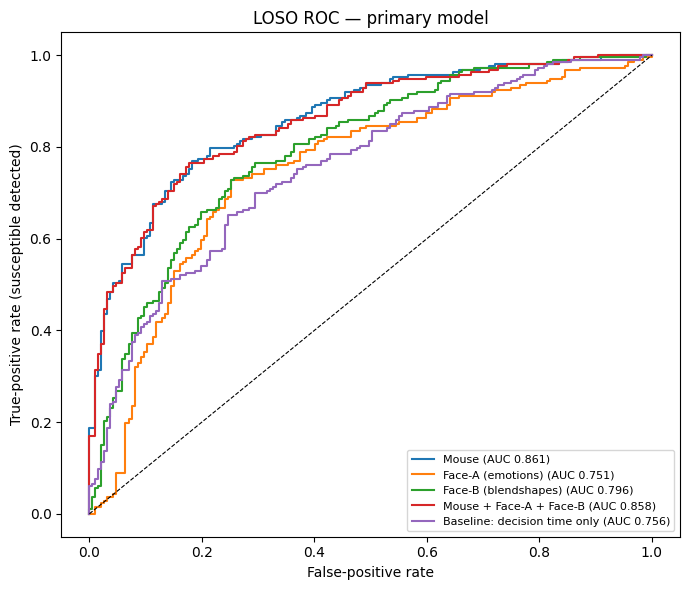

In [40]:
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(figsize=(7, 6))
for label in ["Mouse", "Face-A (emotions)", "Face-B (blendshapes)", "Mouse + Face-A + Face-B", "Baseline: decision time only"]:
    fpr, tpr, _ = roc_curve(y, oofs[MAIN[label]])
    ax.plot(fpr, tpr, label=f"{label} (AUC {compute_metrics(y, oofs[MAIN[label]])['AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=.8)
ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate (susceptible detected)")
ax.set_title("LOSO ROC — primary model"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/roc.png", dpi=150); plt.show()

,mean,std,min,max
mouse,0.9025,0.069752,0.8,1.0
emotion,0.0000,0.000000,0.0,0.0
blend,0.0975,0.069752,0.0,0.2


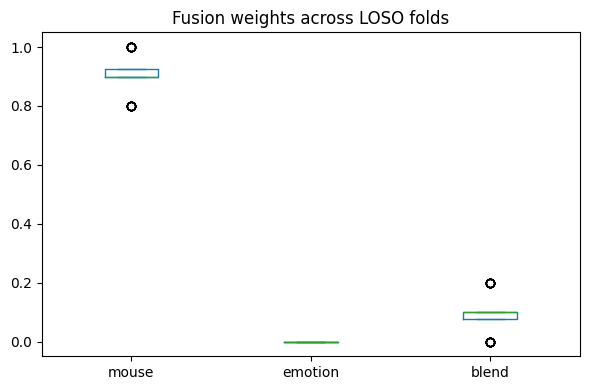

In [41]:
# fusion weights learned in each LOSO fold (decision-level fusion) — how much each modality is trusted
key = MAIN["Mouse + Face-A + Face-B"]
W = pd.DataFrame([np.asarray(w) for w in fold_params[key]], columns=["mouse", "emotion", "blend"])
display(W.describe().T[["mean", "std", "min", "max"]])
fig, ax = plt.subplots(figsize=(6, 4))
W.plot.box(ax=ax, title="Fusion weights across LOSO folds")
plt.tight_layout(); plt.savefig(f"{OUT}/fusion_weights.png", dpi=120); plt.show()

## 5. Explainability (which signals drive the prediction?)
<div dir="rtl">SHAP على نموذج Random Forest مدرّب على كل البيانات (Early fusion لكل الخصائص) — للتفسير فقط وليس للتقييم.</div>

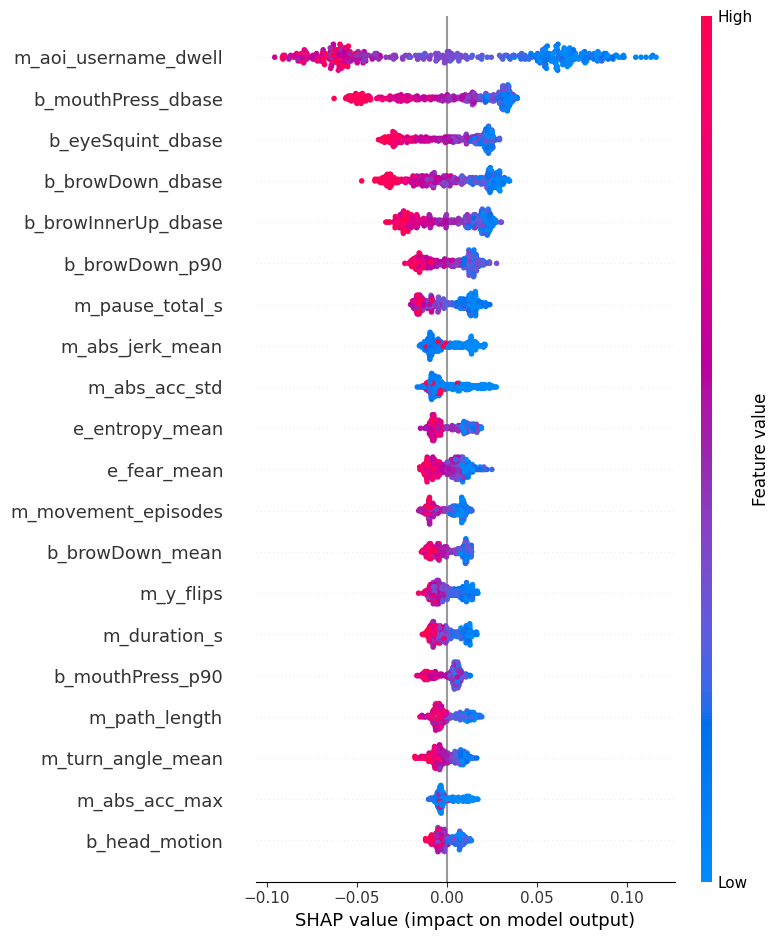

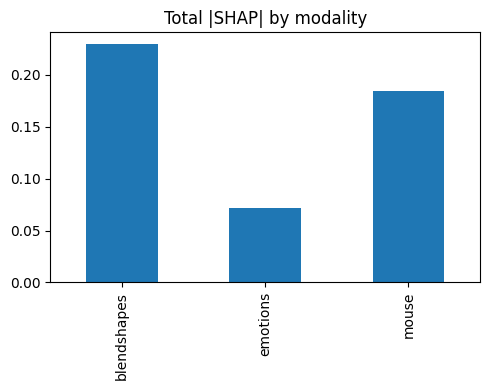

,0
m_aoi_username_dwell,0.054101
b_mouthPress_dbase,0.027043
b_eyeSquint_dbase,0.019350
b_browDown_dbase,0.018811
b_browInnerUp_dbase,0.017673
b_browDown_p90,0.012126
m_pause_total_s,0.012122
m_abs_jerk_mean,0.008933
m_abs_acc_std,0.008456
e_entropy_mean,0.008403


In [42]:
import shap
from sklearn.base import clone
cols = [c for c in data.columns if c.startswith(("m_", "b_", "e_"))]
X = data[cols]
pipe = modeling.make_model("rf", seed=0).fit(X.to_numpy(float), y)
Xt = pipe[:-1].transform(X.to_numpy(float))
kept = np.array(cols)[pipe.named_steps["var"].get_support()]
explainer = shap.TreeExplainer(pipe.named_steps["clf"])
sv = explainer.shap_values(Xt)
sv = sv[1] if isinstance(sv, list) else (sv[..., 1] if sv.ndim == 3 else sv)
plt.figure()
shap.summary_plot(sv, pd.DataFrame(Xt, columns=kept), max_display=20, show=False)
plt.tight_layout(); plt.savefig(f"{OUT}/shap_summary.png", dpi=150); plt.show()
imp = pd.Series(np.abs(sv).mean(0), index=kept).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(5, 4))
imp.groupby(lambda c: c[:2]).sum().rename({"m_": "mouse", "b_": "blendshapes", "e_": "emotions"}).plot.bar(
    ax=ax, title="Total |SHAP| by modality"); plt.tight_layout(); plt.savefig(f"{OUT}/shap_by_modality.png", dpi=120); plt.show()
imp.head(20)

## 6. How early can susceptibility be detected? (objective 7)
<div dir="rtl">نعيد بناء الخصائص من أول N ثانية فقط من كل محاولة، ونقيس أداء النموذج الرئيسي. يتطلب الوصول إلى مجلد الجلسات.</div>

In [43]:
from psd.dataset import WindowConfig, build_trial_table
if USE_SYNTHETIC:
    from psd.synthetic import generate_sessions
    SESSIONS_DIR = str(generate_sessions("/content/synthetic_sessions", n_participants=40, seed=42))
else:
    SESSIONS_DIR = f"{PROJECT_DIR}/experiment_app/data/sessions"
from psd.io import iter_sessions
sessions = list(iter_sessions(SESSIONS_DIR))      # load once, re-window five times
curve = []
for sec in [2, 4, 6, 8, 12]:
    d = build_trial_table(sessions, WindowConfig(end=f"early:{sec}"), verbose=False)
    for mods in [("mouse",), ("blend",), ("mouse", "emotion", "blend")]:
        spec = Spec("x", mods, PRIMARY_MODEL, "none" if len(mods) == 1 else PRIMARY_FUSION)
        r, o, _, dd = run_experiments(d, [spec], verbose=False)
        curve.append({"seconds": sec, "system": " + ".join(MODALITY_LABEL[m] for m in mods), "AUC": r["AUC"].iloc[0]})
curve = pd.DataFrame(curve)
curve.to_csv(f"{OUT}/early_detection.csv", index=False)
ax = curve.pivot(index="seconds", columns="system", values="AUC").plot(marker="o", figsize=(8, 5))
ax.set_ylabel("LOSO AUC"); ax.set_xlabel("first N seconds of the trial"); ax.set_title("Early detection")
plt.tight_layout(); plt.savefig(f"{OUT}/early_detection.png", dpi=150); plt.show()

KeyboardInterrupt: 

## 7. Train the final model for the real-time prototype
<div dir="rtl">

يُدرَّب النموذج الرئيسي على **كل** المشاركين، وتُتعلَّم أوزان الدمج من cross-validation داخلي مجمّع حسب المشارك، ثم يُحفظ في `experiment_app/models/susceptibility_bundle.joblib`.
**مهم:** لاختبار النموذج الأولي (Proof of concept) يجب أن يكون المشاركون في جلسات الـ prototype **أشخاصًا جددًا** لم يشاركوا في جمع بيانات التدريب.
</div>

In [ ]:
import joblib
from psd.modeling import fit_final_bundle
FINAL_MODALITIES = ("mouse", "blend", "emotion")    # drop "emotion" if Face-A adds nothing (section 3)
bundle = fit_final_bundle(df, FINAL_MODALITIES, PRIMARY_MODEL, PRIMARY_FUSION, threshold=0.5, window_cfg=WindowConfig())
print("fusion:", bundle["fusion"], "\ninner-CV AUC per modality:", bundle["inner_cv_auc"])
if not USE_SYNTHETIC:
    path = f"{PROJECT_DIR}/experiment_app/models/susceptibility_bundle.joblib"
    joblib.dump(bundle, path)
    print("saved ->", path)